# Lecture 7 - Expectation, variance, and functions of random variables

This notebook separates **model moments** from **sample estimates**. It uses LOTUS, indicator variables, repeated Monte Carlo experiments, and an outlier diagnostic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 202607
rng = np.random.default_rng(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Equal expectations, different systems

System $X$ takes $1$ ms with probability $0.9$ and $91$ ms with probability $0.1$. System $Y$ always takes $10$ ms. The means coincide, but the PMFs and variances do not.

System X: E[X] = 10.0 ms, Var(X) = 729.0 ms^2
System Y: E[Y] = 10.0 ms, Var(Y) = 0.0 ms^2


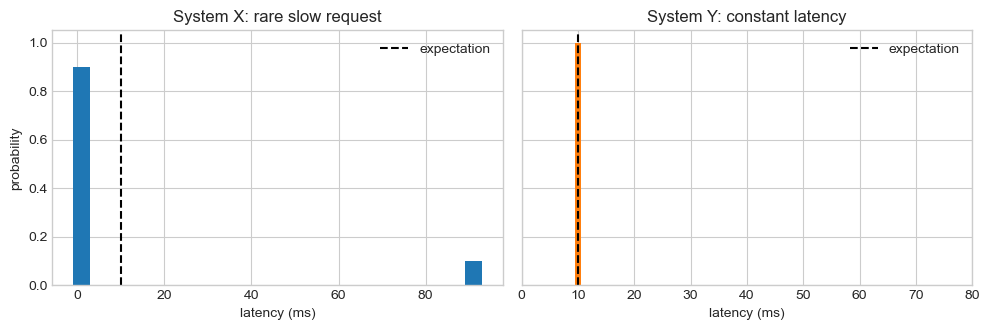

In [10]:
latency_values = np.array([1.0, 91.0])
latency_probabilities = np.array([0.9, 0.1])
latency_mean = np.sum(latency_values * latency_probabilities)
latency_second_moment = np.sum(latency_values**2 * latency_probabilities)
latency_variance = latency_second_moment - latency_mean**2

constant_mean = 10.0
constant_variance = 0.0
print(f"System X: E[X] = {latency_mean:.1f} ms, Var(X) = {latency_variance:.1f} ms^2")
print(f"System Y: E[Y] = {constant_mean:.1f} ms, Var(Y) = {constant_variance:.1f} ms^2")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
axes[0].bar(latency_values, latency_probabilities, width=4, color="tab:blue")
axes[0].axvline(latency_mean, color="black", linestyle="--", label="expectation")
axes[0].set(title="System X: rare slow request", xlabel="latency (ms)", ylabel="probability")
axes[0].legend()
axes[1].bar([10], [1], width=1, color="tab:orange")
axes[1].axvline(constant_mean, color="black", linestyle="--", label="expectation")
axes[1].set(title="System Y: constant latency", xlabel="latency (ms)")
axes[1].legend()
plt.xlim(0,80)
fig.tight_layout()
plt.show()

## 2. LOTUS for a transformation

For $U\sim\operatorname{Unif}(0,1)$ and $V=U^2$, LOTUS gives $\mathbb E[V]=\int_0^1u^2\,\mathrm du=1/3$. The law of $V$ is not required for this calculation, but its density can still be overlaid as a check.

Exact E[U] = 0.500000; Monte Carlo = 0.500056
Exact E[U^2] = 0.333333; Monte Carlo = 0.333385
Exact Var(U^2) = 0.088889; Monte Carlo = 0.088738


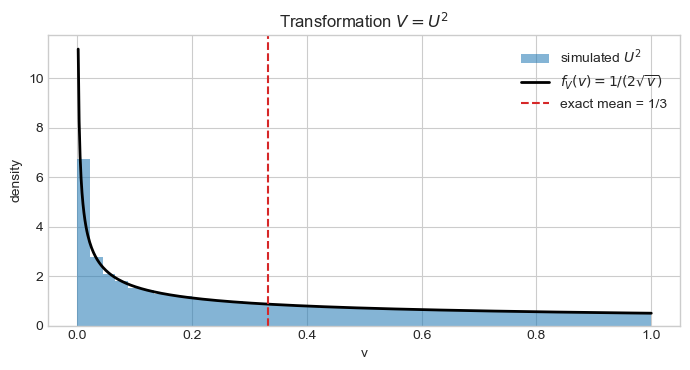

In [25]:
n_samples = 50_000
u_sample = rng.uniform(0.0, 1.0, size=n_samples)
v_sample = u_sample**2
exact_u_mean = 1 / 2
exact_v_mean = 1 / 3
exact_v_second_moment = 1 / 5
exact_v_variance = exact_v_second_moment - exact_v_mean**2

print(f"Exact E[U] = {exact_u_mean:.6f}; Monte Carlo = {u_sample.mean():.6f}")
print(f"Exact E[U^2] = {exact_v_mean:.6f}; Monte Carlo = {v_sample.mean():.6f}")
print(f"Exact Var(U^2) = {exact_v_variance:.6f}; Monte Carlo = {v_sample.var(ddof=1):.6f}")

v_grid = np.linspace(0.002, 1.0, 600)
v_density = 1 / (2 * np.sqrt(v_grid))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(v_sample, bins=45, density=True, alpha=0.55, color="tab:blue", label="simulated $U^2$")
ax.plot(v_grid, v_density, color="black", linewidth=2, label=r"$f_V(v)=1/(2\sqrt{v})$")
ax.axvline(exact_v_mean, color="tab:red", linestyle="--", label="exact mean = 1/3")
ax.set(xlabel="v", ylabel="density", title="Transformation $V=U^2$")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Indicators count distinct labels

If $D_{n,K}$ is the number of distinct labels in $n$ independent uniform draws from $K$ labels, then

$$\mathbb E[D_{n,K}]=K\left[1-\left(1-\frac1K\right)^n\right].$$

The appearance indicators are dependent, but linearity of expectation does not require independence.

,n,exact expectation,Monte Carlo mean,absolute error
0,1,1.0000,1.0000,0.0000
1,5,4.6776,4.6890,0.0114
2,10,8.6259,8.6300,0.0041
3,20,14.7715,14.7465,0.0250
4,40,22.2698,22.2280,0.0418
5,80,28.0081,27.9900,0.0181
6,120,29.4867,29.4820,0.0047


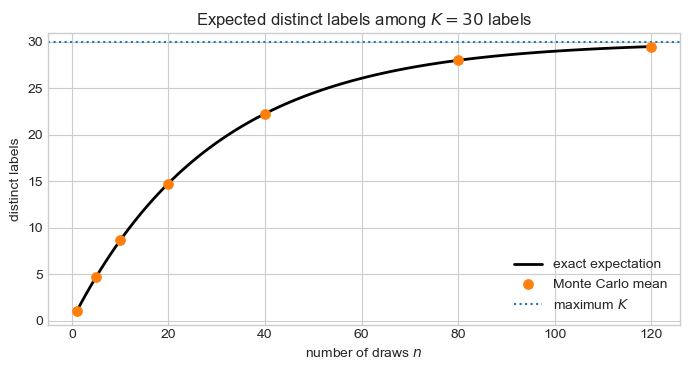

In [27]:
n_labels = 30
n_grid = np.arange(1, 121)
expected_distinct = n_labels * (1 - (1 - 1 / n_labels) ** n_grid)

n_check = np.array([1, 5, 10, 20, 40, 80, 120])
n_replications = 2_000
distinct_mc = []
for n in n_check:
    draws = rng.integers(0, n_labels, size=(n_replications, n))
    sorted_draws = np.sort(draws, axis=1)
    distinct_counts = 1 + np.sum(np.diff(sorted_draws, axis=1) != 0, axis=1)
    distinct_mc.append(distinct_counts.mean())
distinct_mc = np.array(distinct_mc)

comparison = pd.DataFrame({
    "n": n_check,
    "exact expectation": n_labels * (1 - (1 - 1 / n_labels) ** n_check),
    "Monte Carlo mean": distinct_mc,
})
comparison["absolute error"] = np.abs(comparison["Monte Carlo mean"] - comparison["exact expectation"])
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(n_grid, expected_distinct, color="black", linewidth=2, label="exact expectation")
ax.scatter(n_check, distinct_mc, color="tab:orange", s=45, zorder=3, label="Monte Carlo mean")
ax.axhline(n_labels, color="tab:blue", linestyle=":", label="maximum $K$")
ax.set(xlabel="number of draws $n$", ylabel="distinct labels", title=f"Expected distinct labels among $K={n_labels}$ labels")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Repeated Monte Carlo estimation

For $X\sim\operatorname{Exp}(1)$, the exact mean and variance are both one. Repeating the entire simulation separates the random Monte Carlo error from the exact model quantities. For a realized sample $x_{1:n}=(x_1,\ldots,x_n)$, $n\ge2$, the sample variance is

$\widehat\sigma_n^2(x_{1:n})=\frac1{n-1}\sum_{i=1}^n(x_i-\overline x_n)^2.$

It uses `ddof=1`. These are simulation checks of known model moments, not model fitting. The weak and bounded strong laws are proved in Lectures 13-14.

,n,estimator,Monte Carlo mean,empirical bias,empirical RMSE
0,20,mean,1.00763,0.00763,0.22961
1,20,variance,1.02161,0.02161,0.64619
2,200,mean,1.00265,0.00265,0.06967
3,200,variance,1.00524,0.00524,0.20278
4,2000,mean,0.99982,-0.00018,0.02223
5,2000,variance,0.99873,-0.00127,0.06393


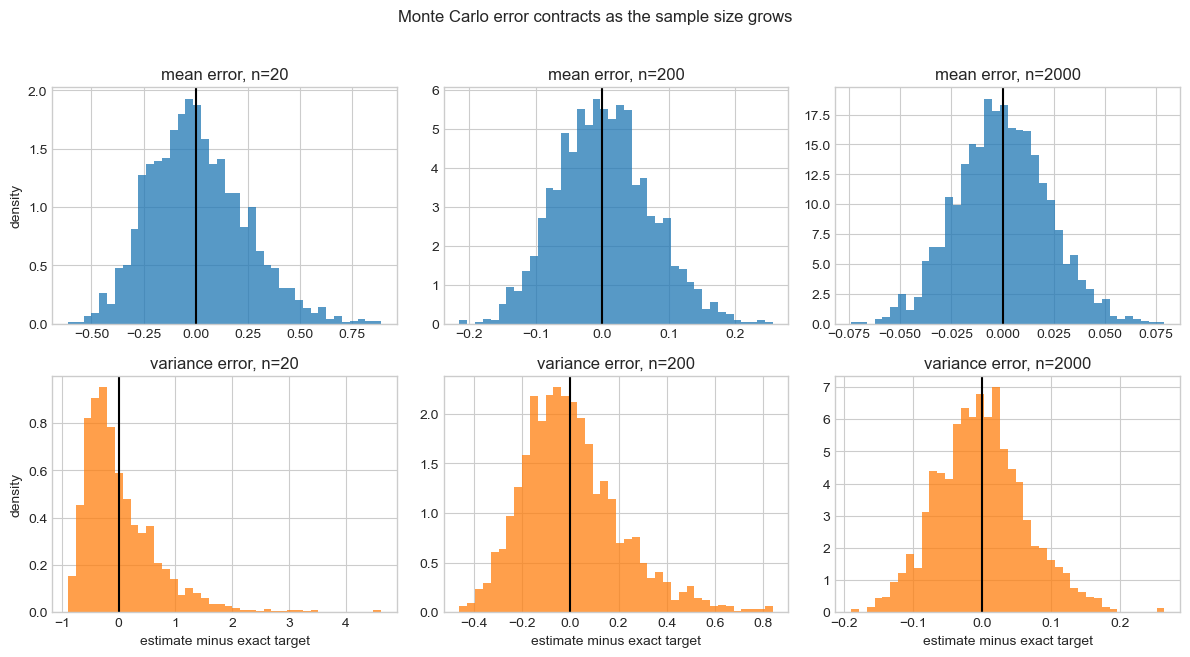

In [18]:
exact_mean = 1.0
exact_variance = 1.0
sample_sizes = np.array([20, 200, 2000])
n_replications = 2_000
moment_results = {}
summary_rows = []

for n in sample_sizes:
    samples = rng.exponential(scale=1.0, size=(n_replications, n))
    sample_means = samples.mean(axis=1)
    sample_variances = samples.var(axis=1, ddof=1)
    moment_results[n] = (sample_means, sample_variances)
    for estimator, estimates, target in [
        ("mean", sample_means, exact_mean),
        ("variance", sample_variances, exact_variance),
    ]:
        errors = estimates - target
        summary_rows.append({
            "n": n,
            "estimator": estimator,
            "Monte Carlo mean": estimates.mean(),
            "empirical bias": errors.mean(),
            "empirical RMSE": np.sqrt(np.mean(errors**2)),
        })

moment_summary = pd.DataFrame(summary_rows)
display(moment_summary.round(5))

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for column, n in enumerate(sample_sizes):
    sample_means, sample_variances = moment_results[n]
    axes[0, column].hist(sample_means - exact_mean, bins=40, density=True, color="tab:blue", alpha=0.75)
    axes[0, column].axvline(0, color="black", linewidth=1.5)
    axes[0, column].set_title(f"mean error, n={n}")
    axes[1, column].hist(sample_variances - exact_variance, bins=40, density=True, color="tab:orange", alpha=0.75)
    axes[1, column].axvline(0, color="black", linewidth=1.5)
    axes[1, column].set_title(f"variance error, n={n}")
    axes[1, column].set_xlabel("estimate minus exact target")
axes[0, 0].set_ylabel("density")
axes[1, 0].set_ylabel("density")
fig.suptitle("Monte Carlo error contracts as the sample size grows", y=1.02)
fig.tight_layout()
plt.show()

## 5. One large observation

Replacing one observation by $100$ is a transparent sensitivity experiment. It is not a rule for deleting or retaining observations; it shows what the summaries measure.

,mean,median,variance (ddof=1)
original sample,0.9500,0.6073,1.0488
one value replaced by 100,1.4489,0.6156,50.0969


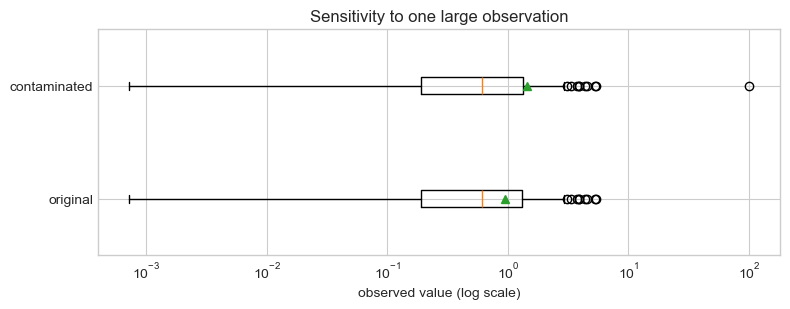

In [23]:
base_sample = rng.exponential(scale=1.0, size=200)
contaminated_sample = base_sample.copy()
contaminated_sample[0] = 100.0

def describe_sample(x):
    return {
        "mean": np.mean(x),
        "median": np.median(x),
        "variance (ddof=1)": np.var(x, ddof=1),
    }

outlier_summary = pd.DataFrame({
    "original sample": describe_sample(base_sample),
    "one value replaced by 100": describe_sample(contaminated_sample),
}).T
display(outlier_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.boxplot([base_sample, contaminated_sample], vert=False, labels=["original", "contaminated"], showmeans=True)
ax.set_xscale("log")
ax.set(xlabel="observed value (log scale)", title="Sensitivity to one large observation")
fig.tight_layout()
plt.show()

## Exercise triad

*Presentation format:* Define the objects and assumptions, show the intermediate argument or computation, and finish with a clear conclusion. For the Python/data task, bring one informative figure and explain what it demonstrates.

1. **Conceptual.** Consider two models for an hourly alert count. Under model A, $X_A\sim\operatorname{Binomial}(4,0.1)$. Under model B, $\mathbb P(X_B=0)=0.96$ and $\mathbb P(X_B=10)=0.04$. Display both PMFs, compute their expectations and variances from the definitions, and calculate $\mathbb P(X_A\ge1)$ and $\mathbb P(X_B\ge1)$. Use the results to explain why an expected count of $0.4$ is meaningful although it is unattainable, and why equal expectations do not imply comparable alert behavior.

2. **Mathematical.** (a) Starting from the definition of variance, prove $\operatorname{Var}(X)=\mathbb E[X^2]-\mathbb E[X]^2$ and $\operatorname{Var}(aX+b)=a^2\operatorname{Var}(X)$. (b) In $n$ independent uniform draws from $\{1,\ldots,K\}$, let $D_{n,K}$ be the number of distinct labels observed. Introduce suitable indicators and derive $\mathbb E[D_{n,K}]$. State explicitly where independence is used and where it is not.

3. **Python/data.** Let $X\sim\operatorname{Exp}(1)$. For each $n\in\{20,200,2000\}$, run $B=2000$ independent simulations and estimate the mean and variance with `np.mean` and `np.var(..., ddof=1)`. Report empirical bias and RMSE for both estimators and compare their error distributions in one figure. Then replace one observation in a sample of size $200$ by $100$ and compare the mean, median, and variance before and after contamination. Explain the distinction between model moments, sample estimates, and Monte Carlo error.